In [287]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/paragchintanwar/insurance/insurance.csv


# 🏥 Insurance Charges Analysis

## Project Overview
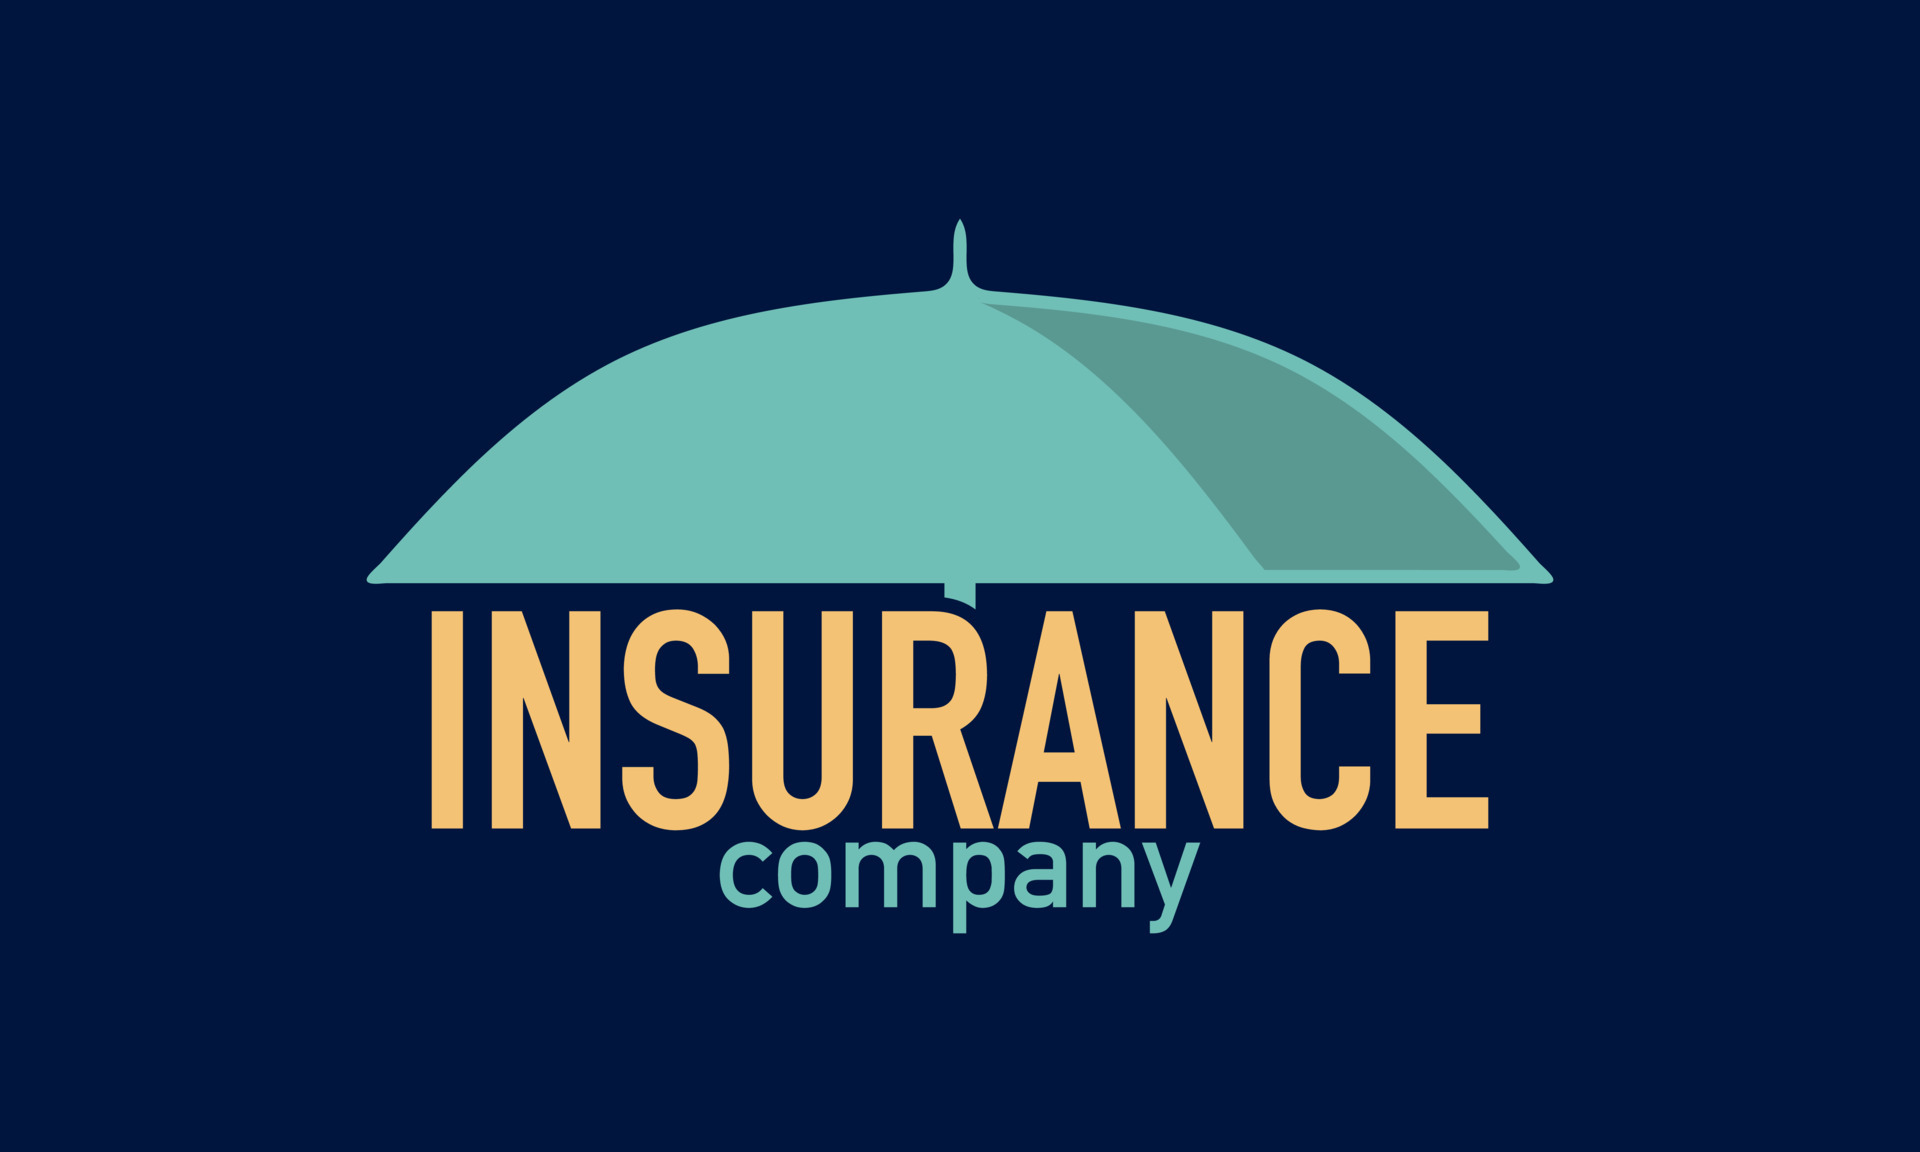
## Project Overview

This project analyzes an insurance dataset containing 1,338 records to understand the factors associated with medical insurance charges.

The analysis focuses on factors such as age, gender, BMI, number of children, smoking status, and region. The project includes data cleaning, duplicate removal, missing value checking, exploratory data analysis, statistical analysis, and data visualization.

The main objective is to identify patterns in insurance charges and understand how different customer characteristics are associated with variations in medical costs.

### Tools Used

* Python
* Pandas
* NumPy
* Matplotlib
* Seaborn
* Jupyter Notebook


In [288]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [289]:
import pandas as pd

df = pd.read_csv("/kaggle/input/datasets/paragchintanwar/insurance/insurance.csv")

print(df.shape)
print(df.head())
print(df.info())

(1338, 7)
   age     sex     bmi  children smoker     region      charges
0   19  female  27.900         0    yes  southwest  16884.92400
1   18    male  33.770         1     no  southeast   1725.55230
2   28    male  33.000         3     no  southeast   4449.46200
3   33    male  22.705         0     no  northwest  21984.47061
4   32    male  28.880         0     no  northwest   3866.85520
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB
None


In [290]:
df.isnull().sum()

age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

In [291]:
df.duplicated().sum()

np.int64(1)

In [292]:
df = df.drop_duplicates()

In [293]:
df.duplicated().sum()

np.int64(0)

### Data Cleaning Note

The original dataset contained 1,338 records. One duplicate record was identified and removed, leaving 1,337 unique records for analysis. No missing values were found.


In [294]:
df.describe()

,age,bmi,children,charges
count,1337.000000,1337.000000,1337.000000,1337.000000
mean,39.222139,30.663452,1.095737,13279.121487
std,14.044333,6.100468,1.205571,12110.359656
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.290000,0.000000,4746.344000
50%,39.000000,30.400000,1.000000,9386.161300
75%,51.000000,34.700000,2.000000,16657.717450
max,64.000000,53.130000,5.000000,63770.428010


In [295]:
print(df["sex"].value_counts())
print()
print(df["smoker"].value_counts())
print()
print(df["region"].value_counts())
print()
print(df["children"].value_counts())

sex
male      675
female    662
Name: count, dtype: int64

smoker
no     1063
yes     274
Name: count, dtype: int64

region
southeast    364
southwest    325
northwest    324
northeast    324
Name: count, dtype: int64

children
0    573
1    324
2    240
3    157
4     25
5     18
Name: count, dtype: int64


In [296]:
print("Age:")
print(df["age"].describe())

print("\nBMI:")
print(df["bmi"].describe())

print("\nCharges:")
print(df["charges"].describe())

Age:
count    1337.000000
mean       39.222139
std        14.044333
min        18.000000
25%        27.000000
50%        39.000000
75%        51.000000
max        64.000000
Name: age, dtype: float64

BMI:
count    1337.000000
mean       30.663452
std         6.100468
min        15.960000
25%        26.290000
50%        30.400000
75%        34.700000
max        53.130000
Name: bmi, dtype: float64

Charges:
count     1337.000000
mean     13279.121487
std      12110.359656
min       1121.873900
25%       4746.344000
50%       9386.161300
75%      16657.717450
max      63770.428010
Name: charges, dtype: float64


In [297]:
df["age"].corr(df["charges"])

np.float64(0.2983082125097864)

In [298]:
df["bmi"].corr(df["charges"])

np.float64(0.19840083122624938)

In [299]:
df.groupby("smoker")["charges"].mean()

smoker
no      8440.660307
yes    32050.231832
Name: charges, dtype: float64

In [300]:
df.groupby("children")["charges"].mean()

children
0    12384.695344
1    12731.171832
2    15073.563734
3    15355.318367
4    13850.656311
5     8786.035247
Name: charges, dtype: float64

In [301]:
df.groupby("region")["charges"].mean()

region
northeast    13406.384516
northwest    12450.840844
southeast    14735.411438
southwest    12346.937377
Name: charges, dtype: float64

In [302]:
df.groupby("sex")["charges"].mean()

sex
female    12569.578844
male      13974.998864
Name: charges, dtype: float64

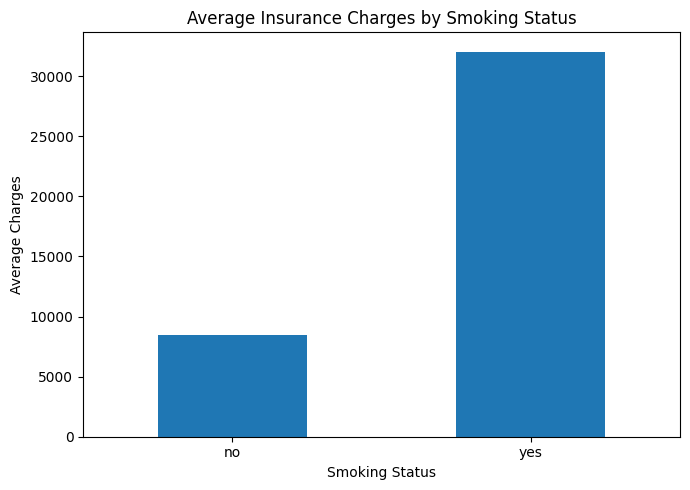

In [303]:
# Average Charges by Smoker

smoker_charges = df.groupby("smoker")["charges"].mean()

smoker_charges.plot(kind="bar", figsize=(7,5))

plt.title("Average Insurance Charges by Smoking Status")
plt.xlabel("Smoking Status")
plt.ylabel("Average Charges")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

### Executive Takeaway

Smokers have substantially higher average insurance charges than non-smokers in this dataset.

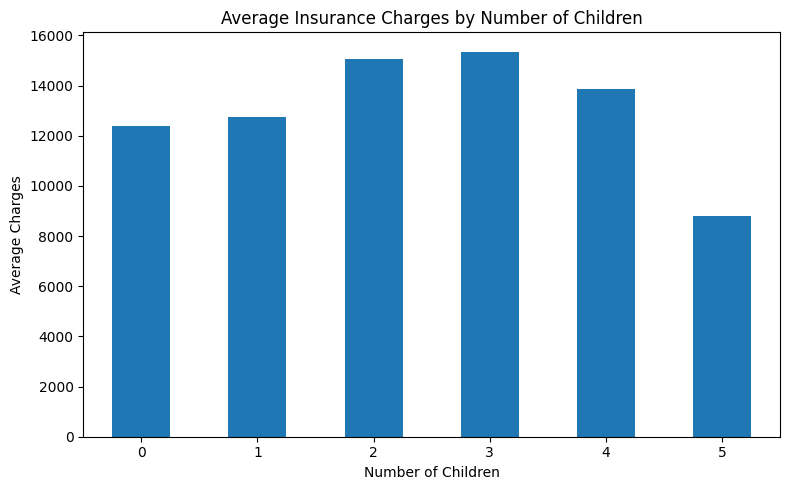

In [304]:
# Average Charges by Number of Children

children_charges = df.groupby("children")["charges"].mean()

children_charges.plot(kind="bar", figsize=(8,5))

plt.title("Average Insurance Charges by Number of Children")
plt.xlabel("Number of Children")
plt.ylabel("Average Charges")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

### Executive Takeaway

Average insurance charges vary across customers with different numbers of children, but the pattern is not consistent across all groups.

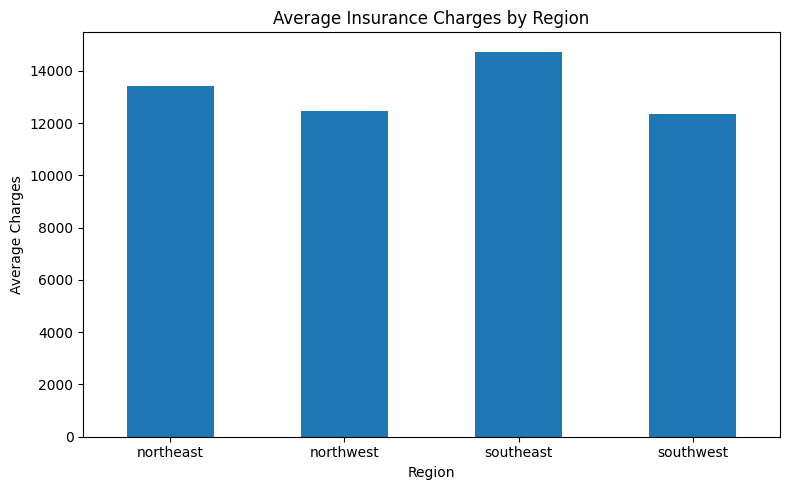

In [305]:
# Average Charges by Region

region_charges = df.groupby("region")["charges"].mean()

region_charges.plot(kind="bar", figsize=(8,5))

plt.title("Average Insurance Charges by Region")
plt.xlabel("Region")
plt.ylabel("Average Charges")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

### Executive Takeaway

Average insurance charges differ across regions, with the Southeast region showing the highest average charges in this dataset.

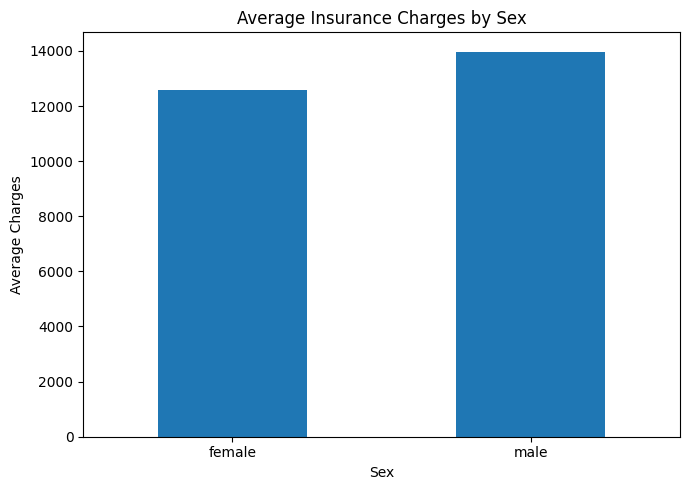

In [306]:
# Average Charges by Sex

sex_charges = df.groupby("sex")["charges"].mean()

sex_charges.plot(kind="bar", figsize=(7,5))

plt.title("Average Insurance Charges by Sex")
plt.xlabel("Sex")
plt.ylabel("Average Charges")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

### Executive Takeaway

Male customers have a higher average insurance charge than female customers in this dataset.

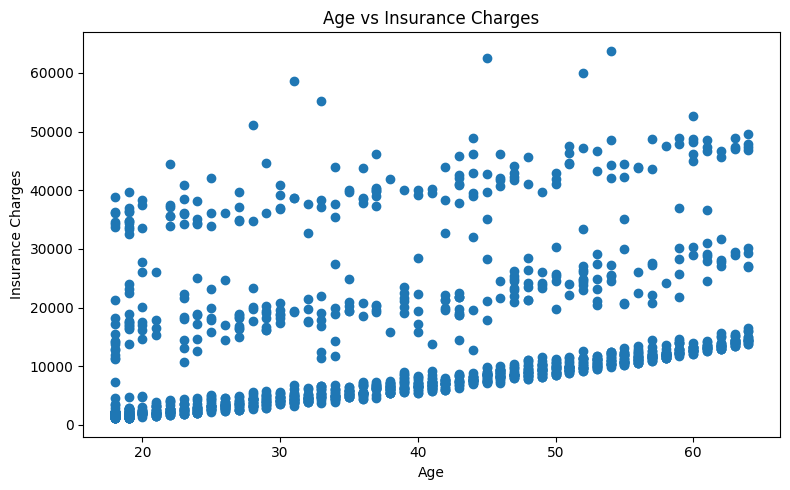

In [307]:
# Age vs Charges

plt.figure(figsize=(8,5))

plt.scatter(df["age"], df["charges"])

plt.title("Age vs Insurance Charges")
plt.xlabel("Age")
plt.ylabel("Insurance Charges")

plt.tight_layout()
plt.show()

### Executive Takeaway

Insurance charges generally tend to increase with age, although there is considerable variation between individual customers.

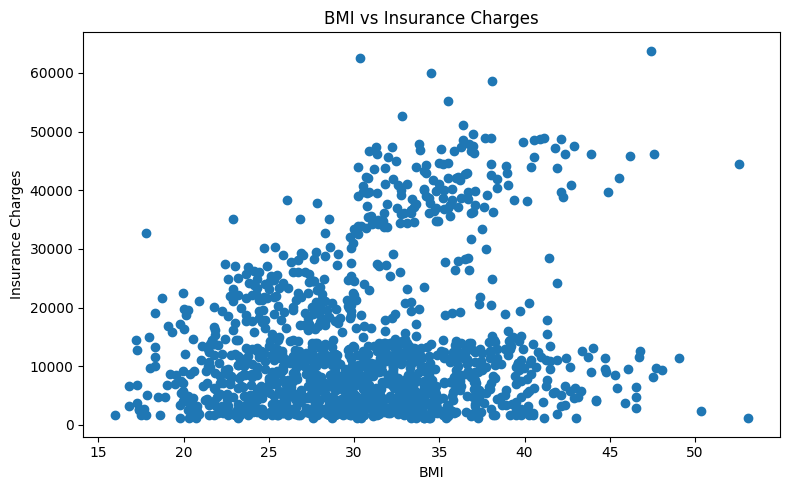

In [308]:
# BMI vs Charges

plt.figure(figsize=(8,5))

plt.scatter(df["bmi"], df["charges"])

plt.title("BMI vs Insurance Charges")
plt.xlabel("BMI")
plt.ylabel("Insurance Charges")

plt.tight_layout()
plt.show()

### Executive Takeaway

BMI shows a positive relationship with insurance charges, although the relationship is weaker than the difference observed by smoking status.

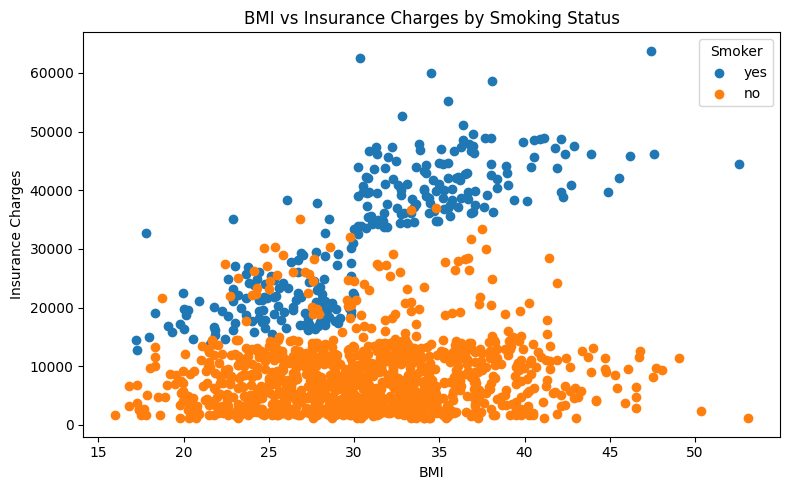

In [309]:
# BMI vs Charges by Smoker

plt.figure(figsize=(8,5))

for smoker_status in df["smoker"].unique():
    smoker_data = df[df["smoker"] == smoker_status]
    plt.scatter(
        smoker_data["bmi"],
        smoker_data["charges"],
        label=smoker_status
    )

plt.title("BMI vs Insurance Charges by Smoking Status")
plt.xlabel("BMI")
plt.ylabel("Insurance Charges")
plt.legend(title="Smoker")

plt.tight_layout()
plt.show()

### Executive Takeaway

Smokers generally have higher insurance charges across different BMI levels compared with non-smokers.

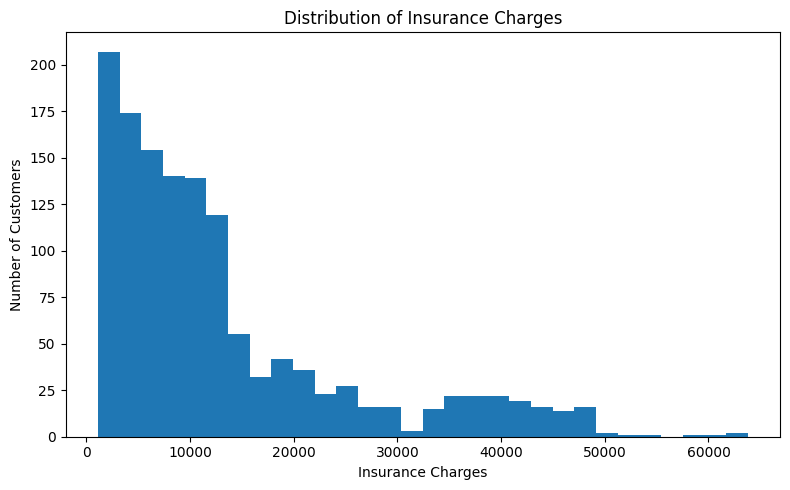

In [310]:
# Charges Distribution

plt.figure(figsize=(8,5))

plt.hist(df["charges"], bins=30)

plt.title("Distribution of Insurance Charges")
plt.xlabel("Insurance Charges")
plt.ylabel("Number of Customers")

plt.tight_layout()
plt.show()

### Executive Takeaway

The distribution of insurance charges is right-skewed, with most customers having lower charges and a smaller number having substantially higher charges.

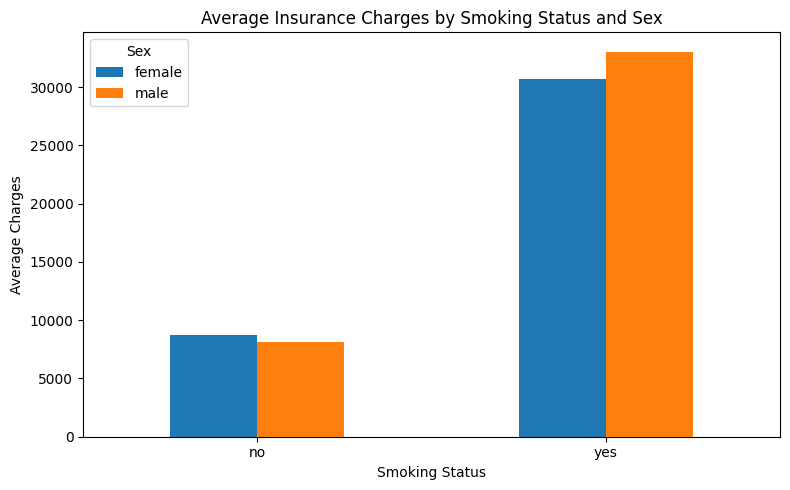

In [311]:
# Charges by Smoker + Sex

smoker_sex_charges = df.groupby(["smoker", "sex"])["charges"].mean().unstack()

smoker_sex_charges.plot(kind="bar", figsize=(8,5))

plt.title("Average Insurance Charges by Smoking Status and Sex")
plt.xlabel("Smoking Status")
plt.ylabel("Average Charges")
plt.xticks(rotation=0)
plt.legend(title="Sex")

plt.tight_layout()
plt.show()

### Executive Takeaway

Smoking status shows a larger difference in average insurance charges than sex, with smokers having substantially higher charges for both groups.

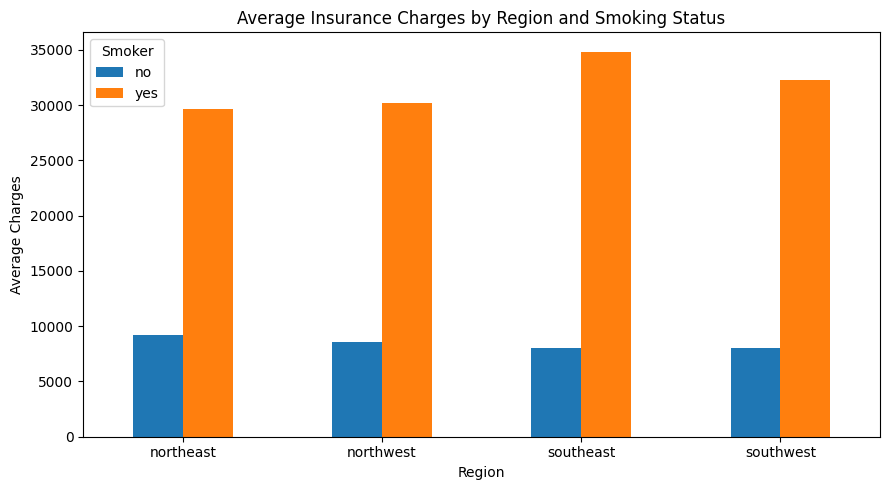

In [312]:
# Region + Smoker Charges

region_smoker_charges = df.groupby(["region", "smoker"])["charges"].mean().unstack()

region_smoker_charges.plot(kind="bar", figsize=(9,5))

plt.title("Average Insurance Charges by Region and Smoking Status")
plt.xlabel("Region")
plt.ylabel("Average Charges")
plt.xticks(rotation=0)
plt.legend(title="Smoker")

plt.tight_layout()
plt.show()

### Executive Takeaway

Smoking status is associated with higher average insurance charges across the different regions in this dataset.

In [313]:
# Create Age Groups

df["age_group"] = pd.cut(
    df["age"],
    bins=[17, 30, 40, 50, 65],
    labels=["18-30", "31-40", "41-50", "51-64"]
)

df["age_group"].value_counts()

age_group
18-30    443
51-64    356
41-50    281
31-40    257
Name: count, dtype: int64

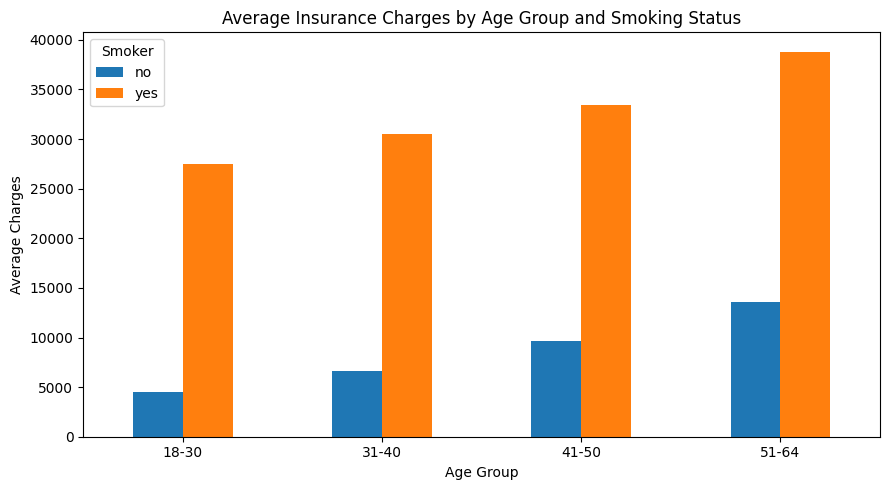

In [314]:
# Age Group + Smoker

age_smoker_charges = df.groupby(
    ["age_group", "smoker"], observed=False
)["charges"].mean().unstack()

age_smoker_charges.plot(kind="bar", figsize=(9,5))

plt.title("Average Insurance Charges by Age Group and Smoking Status")
plt.xlabel("Age Group")
plt.ylabel("Average Charges")
plt.xticks(rotation=0)
plt.legend(title="Smoker")

plt.tight_layout()
plt.show()

### Executive Takeaway

Average insurance charges are generally higher among smokers across age groups, with older smokers showing particularly high charges.

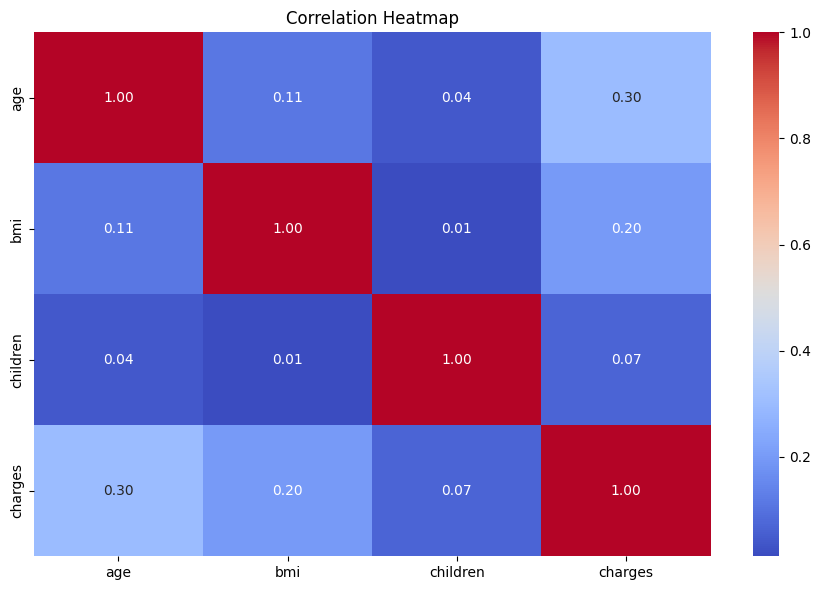

In [315]:
# Correlation Heatmap

plt.figure(figsize=(9,6))

sns.heatmap(
    df.select_dtypes(include="number").corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")

plt.tight_layout()
plt.show()

### Executive Takeaway

The heatmap shows that age has a stronger positive correlation with insurance charges than BMI in this dataset.

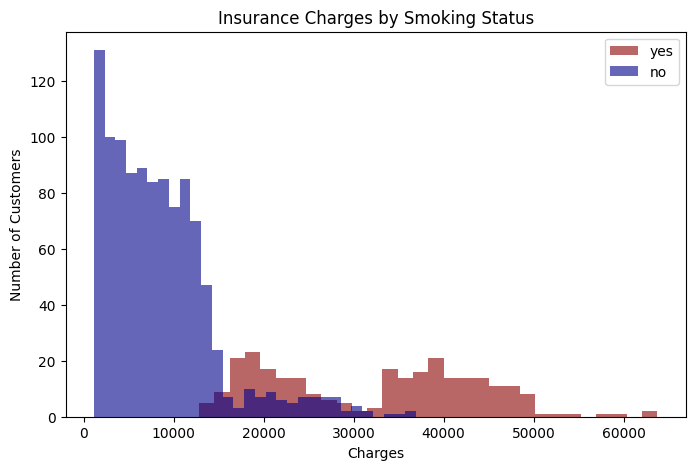

In [316]:
# Insurance Charges Distribution by Smoking Status

plt.figure(figsize=(8,5))

for s in df["smoker"].unique():
    data = df[df["smoker"] == s]
    
    if s == "yes":
        c = "darkred"
    else:
        c = "darkblue"
    
    plt.hist(data["charges"], bins=30, alpha=0.6, color=c, label=s)

plt.title("Insurance Charges by Smoking Status")
plt.xlabel("Charges")
plt.ylabel("Number of Customers")
plt.legend()
plt.show()

### Executive Takeaway

Smokers generally have higher insurance charges than non-smokers, with the smoker distribution concentrated at higher charge levels.

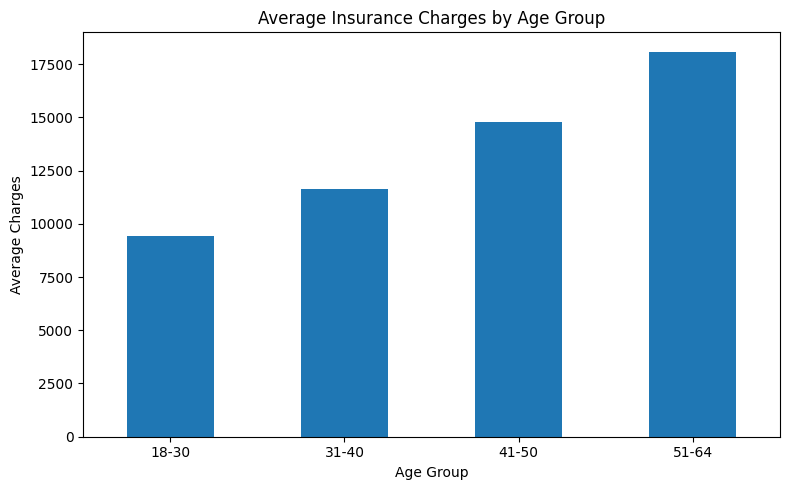

In [317]:
# Average Charges by Age Group

age_group_charges = df.groupby(
    "age_group", observed=False
)["charges"].mean()

age_group_charges.plot(kind="bar", figsize=(8,5))

plt.title("Average Insurance Charges by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Average Charges")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

### Executive Takeaway

Average insurance charges generally increase across the older age groups, indicating higher charges among older customers in this dataset.

In [318]:
# Create BMI Categories

df["bmi_category"] = pd.cut(
    df["bmi"],
    bins=[0, 18.5, 25, 30, 100],
    labels=["Underweight", "Normal", "Overweight", "Obese"]
)

df["bmi_category"].value_counts()

bmi_category
Obese          704
Overweight     386
Normal         226
Underweight     21
Name: count, dtype: int64

bmi_category
Underweight     8657.620652
Normal         10435.440719
Overweight     10997.803881
Obese          15580.700985
Name: charges, dtype: float64


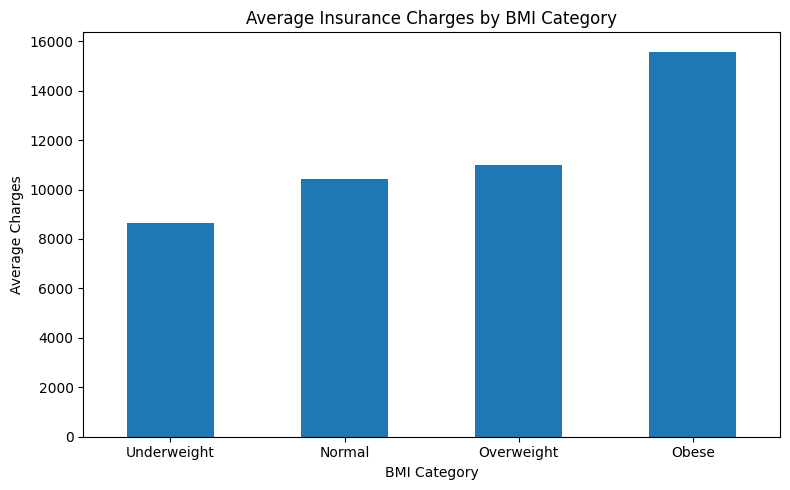

In [319]:
# Average Charges by BMI Category

bmi_charges = df.groupby(
    "bmi_category", observed=True
)["charges"].mean()

print(bmi_charges)

bmi_charges.plot(kind="bar", figsize=(8,5))

plt.title("Average Insurance Charges by BMI Category")
plt.xlabel("BMI Category")
plt.ylabel("Average Charges")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

### Executive Takeaway

Average insurance charges vary across BMI categories, with the Obese category showing the highest average charges in this dataset.

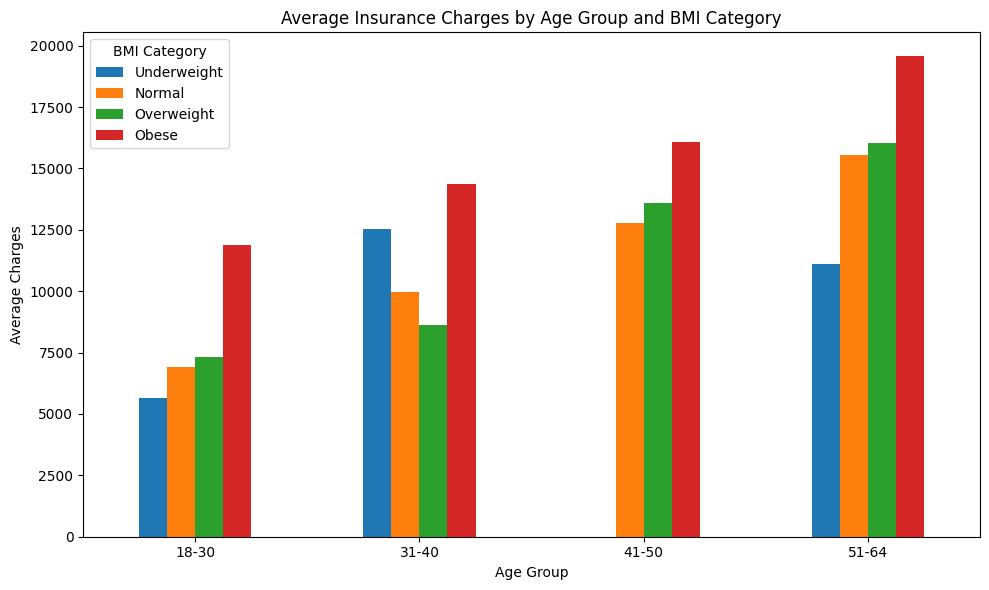

In [320]:
# Average Charges by Age Group and BMI Category

age_bmi_charges = df.groupby(
    ["age_group", "bmi_category"],
    observed=False
)["charges"].mean().unstack()

age_bmi_charges.plot(
    kind="bar",
    figsize=(10,6)
)

plt.title("Average Insurance Charges by Age Group and BMI Category")
plt.xlabel("Age Group")
plt.ylabel("Average Charges")
plt.xticks(rotation=0)
plt.legend(title="BMI Category")

plt.tight_layout()
plt.show()

### Executive Takeaway

Average insurance charges generally increase across older age groups, with higher charges also seen in the Obese BMI category. This suggests that age and BMI together are associated with higher insurance charges in this dataset.

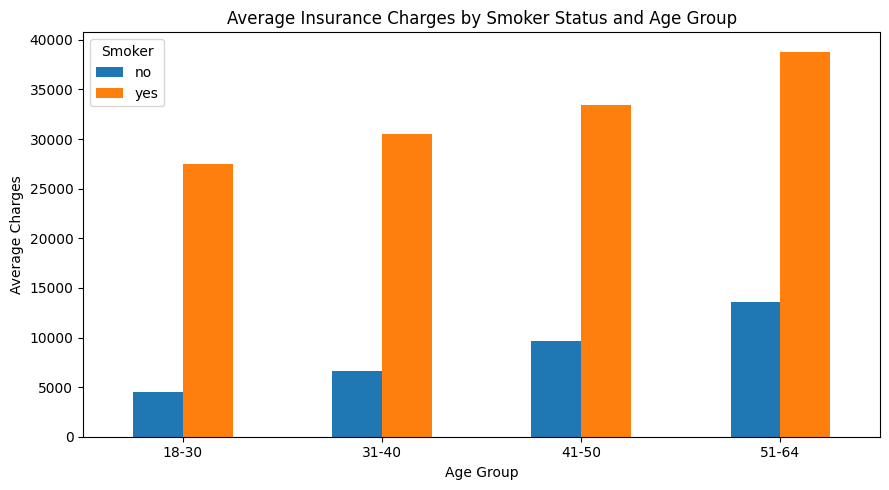

In [321]:
# Average Charges by Smoker and Age Group

smoker_age_charges = df.groupby(
    ["age_group", "smoker"],
    observed=False
)["charges"].mean().unstack()

smoker_age_charges.plot(
    kind="bar",
    figsize=(9,5)
)

plt.title("Average Insurance Charges by Smoker Status and Age Group")
plt.xlabel("Age Group")
plt.ylabel("Average Charges")
plt.xticks(rotation=0)
plt.legend(title="Smoker")

plt.tight_layout()
plt.show()

### Executive Takeaway

Smokers have higher average insurance charges than non-smokers across all age groups, with the difference becoming particularly noticeable in the older age groups.

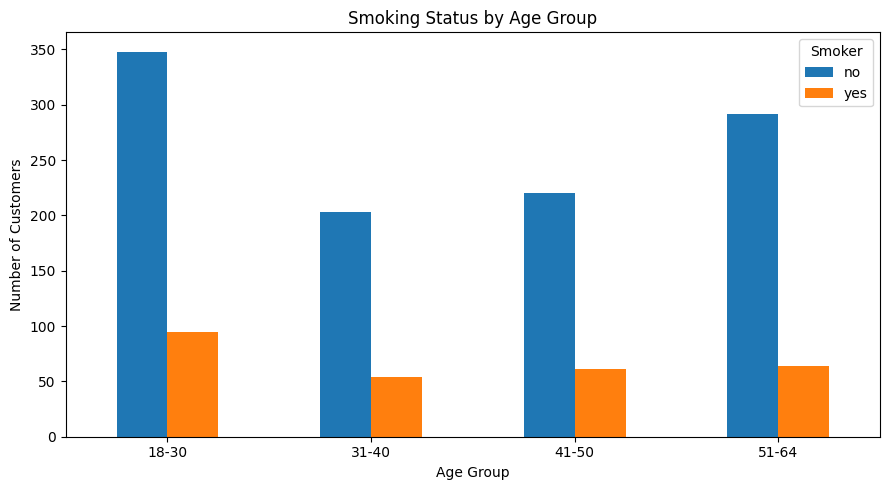

In [322]:
# Smoker Status by Age Group

smoker_age = pd.crosstab(
    df["age_group"],
    df["smoker"]
)

smoker_age.plot(
    kind="bar",
    figsize=(9,5)
)

plt.title("Smoking Status by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Number of Customers")
plt.xticks(rotation=0)
plt.legend(title="Smoker")

plt.tight_layout()
plt.show()

### Executive Takeaway

The number of smokers and non-smokers varies across age groups. Non-smokers are more numerous than smokers in every age group in this dataset.

In [323]:
# Median Insurance Charges by Smoking Status

smoker_median = df.groupby("smoker")["charges"].median()

print(smoker_median)

smoker
no      7345.72660
yes    34456.34845
Name: charges, dtype: float64


In [324]:
# Median Charges Ratio

ratio = smoker_median["yes"] / smoker_median["no"]

print("Smokers have", round(ratio, 2), "times higher median charges than non-smokers.")

Smokers have 4.69 times higher median charges than non-smokers.


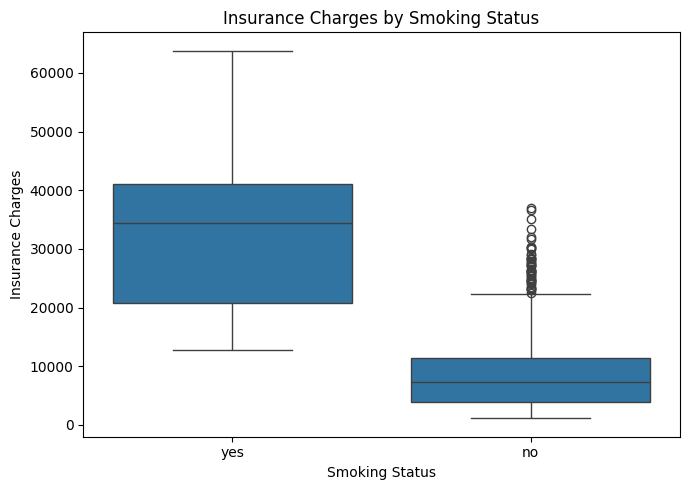

In [325]:
# Charges by Smoking Status

plt.figure(figsize=(7,5))

sns.boxplot(data=df, x="smoker", y="charges")

plt.title("Insurance Charges by Smoking Status")
plt.xlabel("Smoking Status")
plt.ylabel("Insurance Charges")

plt.tight_layout()
plt.show()

### Executive Takeaway

Smokers have substantially higher insurance charges than non-smokers. The median charge for smokers is approximately 4.69 times higher than for non-smokers in this dataset.

bmi_category
Underweight     8657.620652
Normal         10435.440719
Overweight     10997.803881
Obese          15580.700985
Name: charges, dtype: float64


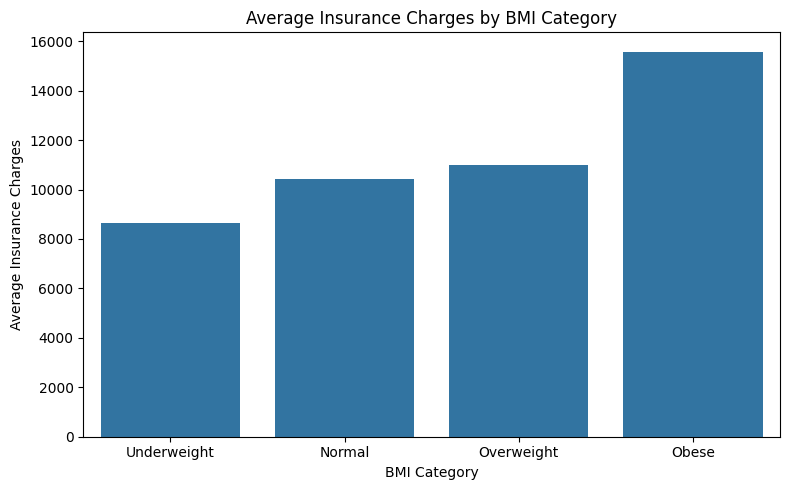

In [326]:
# Average Charges by BMI Category

bmi_charges = df.groupby("bmi_category", observed=True)["charges"].mean()

print(bmi_charges)

plt.figure(figsize=(8,5))

sns.barplot(x=bmi_charges.index, y=bmi_charges.values)

plt.title("Average Insurance Charges by BMI Category")
plt.xlabel("BMI Category")
plt.ylabel("Average Insurance Charges")

plt.tight_layout()
plt.show()

### Executive Takeaway

Average insurance charges vary across BMI categories. The Obese category has the highest average insurance charges, while the Underweight category has the lowest average charges in this dataset.

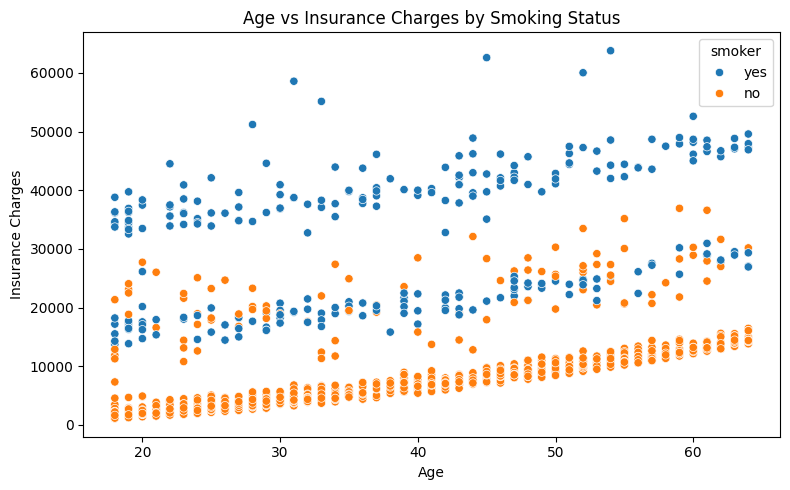

In [327]:
# Age vs Charges by Smoking Status

plt.figure(figsize=(8,5))

sns.scatterplot(
    data=df,
    x="age",
    y="charges",
    hue="smoker"
)

plt.title("Age vs Insurance Charges by Smoking Status")
plt.xlabel("Age")
plt.ylabel("Insurance Charges")

plt.tight_layout()
plt.show()

### Executive Takeaway

The highest insurance charges are mainly observed among older customers who are smokers. This shows that age and smoking status together are associated with higher insurance charges in this dataset.

region
northeast    4.343669e+06
northwest    4.034072e+06
southeast    5.363690e+06
southwest    4.012755e+06
Name: charges, dtype: float64


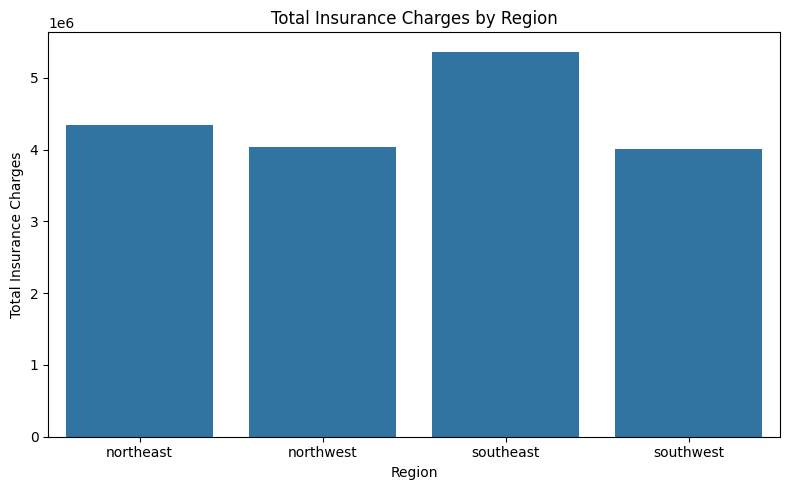

In [328]:
# Total Insurance Charges by Region

region_charges = df.groupby("region")["charges"].sum()

print(region_charges)

plt.figure(figsize=(8,5))

sns.barplot(x=region_charges.index, y=region_charges.values)

plt.title("Total Insurance Charges by Region")
plt.xlabel("Region")
plt.ylabel("Total Insurance Charges")

plt.tight_layout()
plt.show()

### Executive Takeaway

The Southeast region has the highest total insurance charges among all four regions, representing the largest overall financial amount in this dataset.

## Key Insights

* The dataset originally contained 1,338 records, and one duplicate record was removed, leaving 1,337 records for analysis.
* No missing values were found in the dataset.
* Smoking status shows a major difference in insurance charges. The median charge for smokers is approximately 4.69 times higher than for non-smokers.
* Insurance charges vary across BMI categories, with the Obese category showing the highest average charges in this dataset.
* The highest insurance charges are mainly observed among older customers who smoke.
* The Southeast region has the highest total insurance charges among the four regions.
* Overall, smoking status, age, and BMI show important associations with differences in insurance charges in this dataset.


## Conclusion

This project analyzed insurance charges to identify the main factors associated with higher insurance costs.

The analysis found a large difference in median charges between smokers and non-smokers, with smokers having approximately 4.69 times higher median charges. BMI categories also showed differences in average charges, while older smokers occupied the highest-cost range in the age and smoking analysis.

The regional analysis showed that the Southeast region had the highest total insurance charges in the dataset.

Overall, the analysis highlights smoking status, age, BMI, and region as important areas for further review when examining insurance cost patterns.
